# Heart Disease Classification with Voting Ensembles

A reproducible comparison of individual classifiers and hard/soft voting ensembles on the Heart Failure Prediction dataset. The notebook focuses on a sound evaluation workflow: stratified holdout data, preprocessing fitted inside each pipeline, and probability-based ranking metrics.

> **Scope:** This is an educational machine-learning exercise. The dataset is small and observational; model output is not a diagnosis and must not guide clinical care.

## Project at a glance

- **Question:** Can a small set of routinely recorded features distinguish records labeled with heart disease in this dataset?
- **Target:** `HeartDisease` (`1` = positive label, `0` = negative label).
- **Approach:** Compare Logistic Regression, Random Forest, Extra Trees and Support Vector Machine models with hard and soft voting.
- **Evaluation:** A stratified 30% holdout set, ROC-AUC, average precision, precision, recall, F1 and accuracy. Five-fold cross-validation is run on training data only.

## Contents

1. [Setup and data](#1-setup-and-data)
2. [Data checks and exploration](#2-data-checks-and-exploration)
3. [Preprocessing and split](#3-preprocessing-and-split)
4. [Models and evaluation](#4-models-and-evaluation)
5. [Voting ensembles](#5-voting-ensembles)
6. [Interpretation and limitations](#6-interpretation-and-limitations)

## 1. Setup and data

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier, VotingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    RocCurveDisplay,
    roc_auc_score,
)
from sklearn.model_selection import cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
warnings.filterwarnings("ignore", category=FutureWarning)

### Load the CSV

Download `heart.csv` from the Kaggle dataset linked in the project README and place it in `data/raw/heart.csv`. The fallback paths support Kaggle notebooks and a CSV alongside this notebook.

In [2]:
candidate_paths = [
    Path("data/raw/heart.csv"),
    Path("../data/raw/heart.csv"),
    Path("heart.csv"),
    Path("../input/heart-failure-prediction/heart.csv"),
]
data_path = next((path for path in candidate_paths if path.exists()), None)
if data_path is None:
    searched = "\n".join(f"- {path}" for path in candidate_paths)
    raise FileNotFoundError(
        "heart.csv was not found. Download the dataset and save it to "
        "data/raw/heart.csv. Searched:\n" + searched
    )

df = pd.read_csv(data_path)
print(f"Loaded {len(df):,} rows and {df.shape[1]} columns from {data_path}")
display(df.head())

Loaded 918 rows and 12 columns from ..\data\raw\heart.csv


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


## 2. Data checks and exploration

Check the schema, target balance, duplicate rows and missing values before modeling. This dataset does not provide a patient identifier, so identical rows cannot safely be assumed to be duplicate patients; they are retained.

In [3]:
TARGET = "HeartDisease"
required_columns = {TARGET}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"Required target column is missing: {sorted(missing_columns)}")

print("Shape:", df.shape)
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Missing values by column:")
display(df.isna().sum().rename("missing").to_frame().query("missing > 0"))
print("\nColumn types:")
display(df.dtypes.rename("dtype").to_frame())
print("\nTarget counts:")
display(df[TARGET].value_counts(dropna=False).rename_axis(TARGET).to_frame("records"))

Shape: (918, 12)
Exact duplicate rows: 0
Missing values by column:


,missing



Column types:


,dtype
Age,int64
Sex,object
ChestPainType,object
RestingBP,int64
Cholesterol,int64
FastingBS,int64
RestingECG,object
MaxHR,int64
ExerciseAngina,object
Oldpeak,float64



Target counts:


,records
HeartDisease,
1,508
0,410


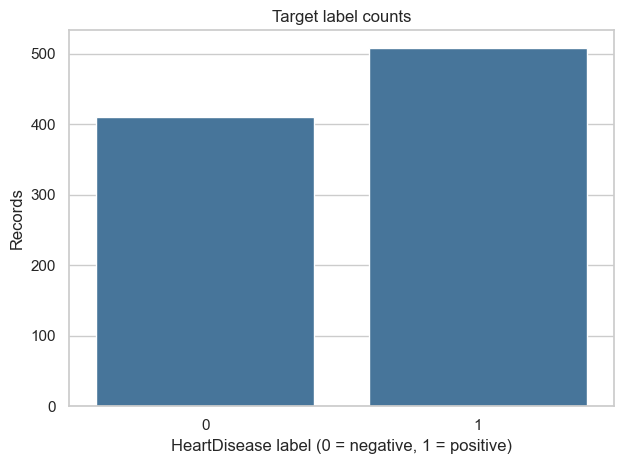

In [4]:
target_counts = df[TARGET].value_counts().sort_index()
ax = sns.barplot(x=target_counts.index.astype(str), y=target_counts.values, color="#3976a8")
ax.set(title="Target label counts", xlabel="HeartDisease label (0 = negative, 1 = positive)", ylabel="Records")
plt.tight_layout()
plt.show()

The target distribution gives context for interpreting accuracy. In particular, recall and average precision can be useful alongside accuracy when the two labels are not equally common.

In [5]:
numeric_columns = df.drop(columns=TARGET).select_dtypes(include="number").columns.tolist()
categorical_columns = df.drop(columns=TARGET).select_dtypes(exclude="number").columns.tolist()
print(f"Numeric features ({len(numeric_columns)}): {numeric_columns}")
print(f"Categorical features ({len(categorical_columns)}): {categorical_columns}")

if numeric_columns:
    display(df[numeric_columns].describe().T.round(2))

Numeric features (6): ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']
Categorical features (5): ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']


,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.51,9.43,28.0,47.00,54.0,60.0,77.0
RestingBP,918.0,132.40,18.51,0.0,120.00,130.0,140.0,200.0
Cholesterol,918.0,198.80,109.38,0.0,173.25,223.0,267.0,603.0
FastingBS,918.0,0.23,0.42,0.0,0.00,0.0,0.0,1.0
MaxHR,918.0,136.81,25.46,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.89,1.07,-2.6,0.00,0.6,1.5,6.2


## 3. Preprocessing and split

No rows are removed using full-dataset outlier thresholds: that would discard potentially meaningful clinical measurements and let holdout data influence preparation. Imputation, scaling and encoding are instead fitted within each training fold by a scikit-learn pipeline.

In [6]:
if df[TARGET].isna().any():
    raise ValueError("The target column contains missing labels; resolve them before training.")
if not set(df[TARGET].unique()).issubset({0, 1}):
    raise ValueError("Expected HeartDisease labels encoded as 0 and 1.")

X = df.drop(columns=TARGET).copy()
y = df[TARGET].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=RANDOM_STATE,
)
print(f"Training rows: {len(X_train):,} | Test rows: {len(X_test):,}")
print("Positive-label share ? train:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))

Training rows: 642 | Test rows: 276
Positive-label share ? train: 0.553 | test: 0.554


In [7]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns),
])

def make_pipeline(classifier):
    """Create a fresh preprocessing + classifier pipeline."""
    return Pipeline(steps=[("preprocess", preprocessor), ("classifier", classifier)])

## 4. Models and evaluation

The baseline models use fixed random seeds where supported. Each model receives the same holdout split and preprocessing strategy.

In [8]:
base_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2_000,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=1,
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=1,
    ),
    "RBF SVM": SVC(
        C=1.0,
        kernel="rbf",
        probability=True,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
}

fitted_models = {}
for name, classifier in base_models.items():
    model = make_pipeline(classifier)
    model.fit(X_train, y_train)
    fitted_models[name] = model
print(f"Fitted {len(fitted_models)} baseline models.")

Fitted 4 baseline models.


In [9]:
def evaluate_model(name, model, X_eval, y_eval):
    """Return holdout metrics at the default 0.50 classification threshold."""
    predictions = model.predict(X_eval)
    classifier = model.named_steps["classifier"]
    if isinstance(classifier, VotingClassifier) and classifier.voting == "hard":
        roc_auc = np.nan
        average_precision = np.nan
    else:
        probabilities = model.predict_proba(X_eval)[:, 1]
        roc_auc = roc_auc_score(y_eval, probabilities)
        average_precision = average_precision_score(y_eval, probabilities)
    return {
        "Model": name,
        "ROC-AUC": roc_auc,
        "Average precision": average_precision,
        "Precision": precision_score(y_eval, predictions, zero_division=0),
        "Recall": recall_score(y_eval, predictions, zero_division=0),
        "F1": f1_score(y_eval, predictions, zero_division=0),
        "Accuracy": accuracy_score(y_eval, predictions),
    }

results = [
    evaluate_model(name, model, X_test, y_test)
    for name, model in fitted_models.items()
]
results_df = pd.DataFrame(results).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
display(results_df.style.format({column: "{:.3f}" for column in results_df.columns if column != "Model"}))

,Model,ROC-AUC,Average precision,Precision,Recall,F1,Accuracy
0,RBF SVM,0.951,0.954,0.899,0.928,0.913,0.902
1,Random Forest,0.945,0.946,0.904,0.928,0.916,0.906
2,Extra Trees,0.942,0.944,0.899,0.928,0.913,0.902
3,Logistic Regression,0.932,0.944,0.906,0.882,0.894,0.884


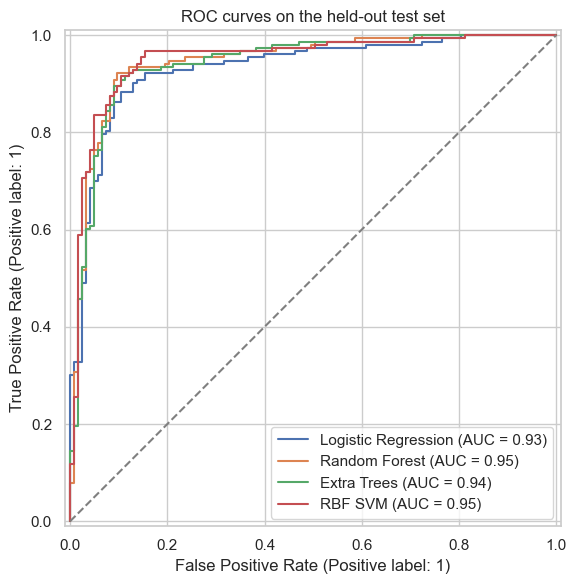

In [10]:
fig, ax = plt.subplots(figsize=(8, 6))
for name, model in fitted_models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Chance")
ax.set_title("ROC curves on the held-out test set")
plt.tight_layout()
plt.show()

Classification report for the highest ROC-AUC baseline:
              precision    recall  f1-score   support

           0       0.91      0.87      0.89       123
           1       0.90      0.93      0.91       153

    accuracy                           0.90       276
   macro avg       0.90      0.90      0.90       276
weighted avg       0.90      0.90      0.90       276



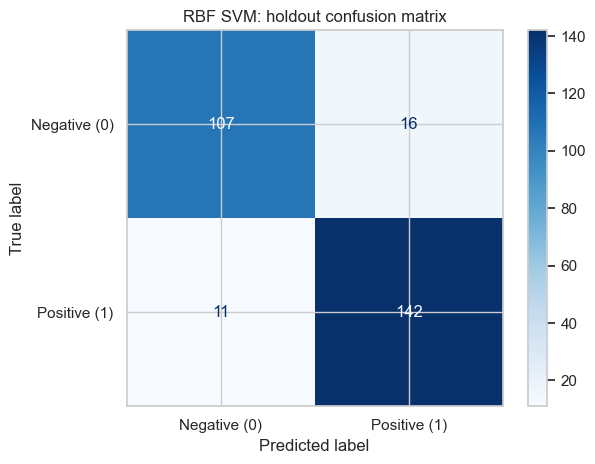

In [11]:
best_baseline_name = results_df.loc[0, "Model"]
best_baseline = fitted_models[best_baseline_name]
print("Classification report for the highest ROC-AUC baseline:")
print(classification_report(y_test, best_baseline.predict(X_test), zero_division=0))
ConfusionMatrixDisplay.from_estimator(
    best_baseline,
    X_test,
    y_test,
    display_labels=["Negative (0)", "Positive (1)"],
    cmap="Blues",
)
plt.title(f"{best_baseline_name}: holdout confusion matrix")
plt.tight_layout()
plt.show()

### Cross-validation on training data

The test set remains untouched during cross-validation. The folds refit the full pipeline each time, so imputation, scaling and encoding do not learn from validation rows.

In [12]:
scoring = {
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "recall": "recall",
    "f1": "f1",
}
cv_rows = []
for name, classifier in base_models.items():
    scores = cross_validate(
        make_pipeline(classifier),
        X_train,
        y_train,
        cv=5,
        scoring=scoring,
        n_jobs=1,
        return_train_score=False,
    )
    cv_rows.append({
        "Model": name,
        **{metric: scores[f"test_{metric}"].mean() for metric in scoring},
        **{f"{metric} SD": scores[f"test_{metric}"].std(ddof=1) for metric in scoring},
    })
cv_results = pd.DataFrame(cv_rows).sort_values("roc_auc", ascending=False).reset_index(drop=True)
display(cv_results.style.format({column: "{:.3f}" for column in cv_results.columns if column != "Model"}))

,Model,roc_auc,average_precision,recall,f1,roc_auc SD,average_precision SD,recall SD,f1 SD
0,Random Forest,0.920,0.926,0.882,0.865,0.050,0.058,0.031,0.019
1,Logistic Regression,0.914,0.924,0.854,0.859,0.057,0.055,0.043,0.049
2,RBF SVM,0.913,0.920,0.882,0.868,0.052,0.061,0.029,0.027
3,Extra Trees,0.913,0.915,0.885,0.869,0.062,0.069,0.036,0.045


## 5. Voting ensembles

Hard voting takes the majority class predicted by each base model. Soft voting averages predicted class probabilities. Both ensembles use the same preprocessing pipeline for each member.

In [13]:
voting_estimators = [
    ("logistic", base_models["Logistic Regression"]),
    ("forest", base_models["Random Forest"]),
    ("extra_trees", base_models["Extra Trees"]),
    ("svm", base_models["RBF SVM"]),
]

def make_voting_pipeline(voting):
    ensemble = VotingClassifier(estimators=voting_estimators, voting=voting, n_jobs=1)
    return make_pipeline(ensemble)

hard_voting = make_voting_pipeline("hard").fit(X_train, y_train)
soft_voting = make_voting_pipeline("soft").fit(X_train, y_train)

ensemble_results = pd.DataFrame([
    evaluate_model("Hard Voting", hard_voting, X_test, y_test),
    evaluate_model("Soft Voting", soft_voting, X_test, y_test),
])
display(ensemble_results.style.format({column: "{:.3f}" for column in ensemble_results.columns if column != "Model"}))

,Model,ROC-AUC,Average precision,Precision,Recall,F1,Accuracy
0,Hard Voting,nan,nan,0.904,0.922,0.913,0.902
1,Soft Voting,0.947,0.951,0.911,0.935,0.923,0.913


### Cross-validated ensemble comparison

Compare ensembles on the training split with the same five-fold protocol. These cross-validation results are not a substitute for external validation on a new population.

In [14]:
ensemble_cv_rows = []
for voting in ("hard", "soft"):
    # Hard voting has no probability ranking, so ROC-AUC and average precision do not apply.
    ensemble_scoring = scoring if voting == "soft" else {"recall": "recall", "f1": "f1"}
    scores = cross_validate(
        make_voting_pipeline(voting),
        X_train,
        y_train,
        cv=5,
        scoring=ensemble_scoring,
        n_jobs=1,
        return_train_score=False,
    )
    ensemble_cv_rows.append({
        "Model": f"{voting.title()} Voting",
        **{metric: scores[f"test_{metric}"].mean() for metric in ensemble_scoring},
        **{f"{metric} SD": scores[f"test_{metric}"].std(ddof=1) for metric in ensemble_scoring},
    })
ensemble_cv_results = pd.DataFrame(ensemble_cv_rows).sort_values("roc_auc", ascending=False)
display(ensemble_cv_results.style.format({column: "{:.3f}" for column in ensemble_cv_results.columns if column != "Model"}))

,Model,recall,f1,recall SD,f1 SD,roc_auc,average_precision,roc_auc SD,average_precision SD
1,Soft Voting,0.890,0.876,0.034,0.034,0.922,0.929,0.055,0.060
0,Hard Voting,0.868,0.869,0.032,0.041,nan,nan,nan,nan


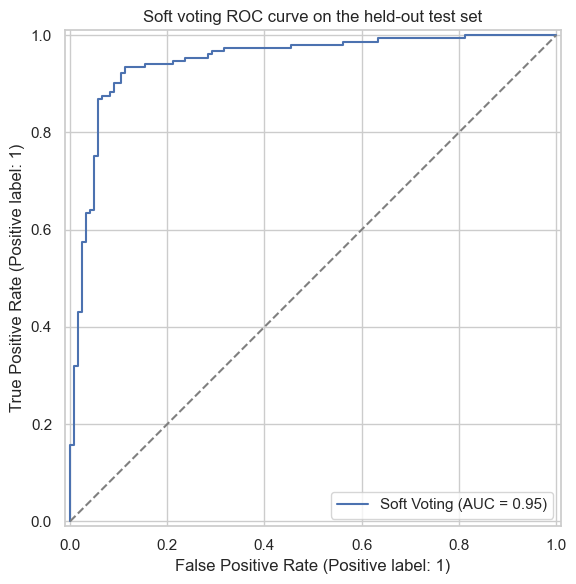

In [15]:
fig, ax = plt.subplots(figsize=(8, 6))
RocCurveDisplay.from_estimator(soft_voting, X_test, y_test, name="Soft Voting", ax=ax)
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Chance")
ax.set_title("Soft voting ROC curve on the held-out test set")
plt.tight_layout()
plt.show()

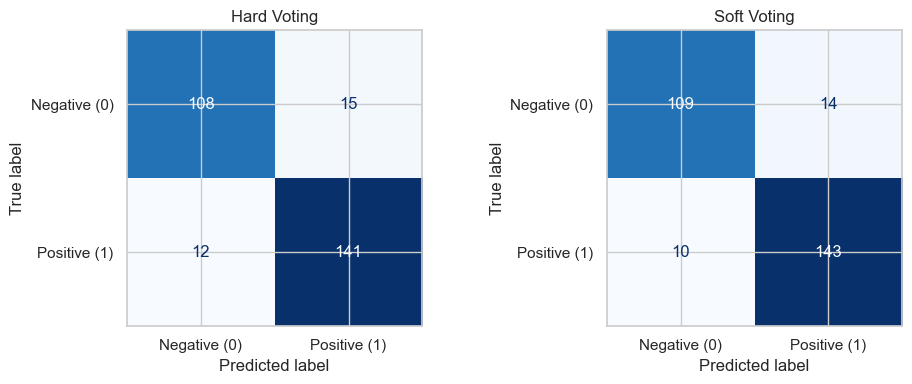

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, model) in zip(axes, {"Hard Voting": hard_voting, "Soft Voting": soft_voting}.items()):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test,
        display_labels=["Negative (0)", "Positive (1)"],
        cmap="Blues", ax=ax, colorbar=False,
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

## Sources and attribution

Dataset: [Heart Failure Prediction](https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction), by Federico Sorian. The supplied notebook was the starting point for this reorganization; its topic and reference links are credited below, while the preprocessing, model setup and evaluation workflow have been rewritten.

- [Voting Classifier overview](https://www.geeksforgeeks.org/ml-voting-classifier-using-sklearn/)
- [EnsembleVoteClassifier documentation](http://rasbt.github.io/mlxtend/user_guide/classifier/EnsembleVoteClassifier/)
- [Voting Classifier discussion, Analytics Vidhya](https://medium.com/analytics-vidhya/voting-classifier-in-machine-learning-9534504eba39)
- The supplied notebook also referenced articles by Towards Data Science and Kaggle notebooks on cross-validation, EDA, class imbalance and outlier detection.
